In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/3")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "3":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 3.1 QEMUモニタ (`QEMU Monitor and Debugging`)
## — ベアメタル初期化・カーネルクラッシュを救う非侵襲ハードウェアインスペクタの全貌

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.1_QEMU_Monitor_and_Debugging.ipynb)

本節は、『ゼロからのOS自作入門』**第3章 画面表示の練習とブートローダ**の第1節 **「3.1 QEMUモニタ」** に対応する完全自己完結型解説ノートブックです。

第2章までは、UEFI BIOS と EDK II の提供するブートサービス（Boot Services）に完全に頼り、UEFI 標準の画面出力プロトコル（`ConOut->OutputString`）やファイル出力（`SimpleFileSystem`）を用いて文字列やメモリマップ CSV を確認してきました。

しかし、第3章以降、いよいよ自作OSの核心である**「カーネル（Kernel）」**のロードと実行に突入します。
カーネルへ制御をジャンプさせた瞬間、まだ自作の画面描画ドライバも、フォントレンダラも、`printf` や `printk` も存在しない**「完全な闇の世界（Bare Metal）」**に放り出されます。

もしカーネルのアドレス計算を1バイト間違えていたら？
もしページングやセグメントの設定が不正でトリプルフォールト（Triple Fault: CPU即死リセット）を起こしたら？
画面には一切何も表示されず、OS はただフリーズするか再起動ループに陥るだけです。

この**「OS自作初期最大の壁」**を突破するための最強の武器が、本節で学ぶ **「QEMUモニタ (QEMU Monitor)」** です。

---

### 🎯 本節の到達目標 (Learning Objectives)

1. **QEMUモニタの存在意義と非侵襲デバッグの理解**:
   - 画面表示もシリアル出力も未実装なベアメタル初期化フェーズにおける、ハードウェアデバッガとしての QEMU モニタの絶対的優位性を説明できる。
   - プログラムの実行を妨げたりメモリを破壊したりしない「非侵襲的（Non-intrusive / Probe Effect ゼロ）」な観察手法を理解する。
2. **QEMUモニタの起動・操作モードの完全習得**:
   - GUI モード（`Ctrl + Alt + 2` と `Ctrl + Alt + 1` によるコンソール切替）および CLI / ソケットモード（`-monitor stdio` 等）を使いこなせる。
3. **`info registers` による CPU 内部状態の完全解読**:
   - 64ビット汎用レジスタ（RAX〜R15）、命令ポインタ（RIP）、スタックポインタ（RSP）、フラグレジスタ（RFLAGS）の値を検査できる。
   - 制御レジスタ（CR0, CR2, CR3, CR4）から、プロテクトモード（PE）、ページング（PG）、ページテーブルルート（CR3）、SSE（CR4）の有効化状態を診断できる。
4. **`xp` (eXamine Physical memory) コマンドによる物理メモリ検査**:
   - 構文 `/nuf <address>`（カウント $n$、単位 $u$、書式 $f$）を自在に指定し、物理メモリ上のバイト列・機械語・ポインタ値を直接ダンプできる。
   - x86-64 の**リトルエンディアン（Little-Endian）**特性を理解し、生バイト列と多バイト整数（16bit / 32bit / 64bit）の対応関係を数理的に解釈できる。
5. **C++20 & Python によるシミュレーションと実践**:
   - ホスト側 C++20 および Python 上で QEMU モニタのコマンド解析・メモリダンプ機構を再現し、対話的なインスペクションを体験する。

---

### 📚 重要技術用語一覧 (Technical Glossary)

| 用語 | 英語正式名称 | 本節での役割・定義 |
|---|---|---|
| **QEMUモニタ** | **QEMU Monitor** | QEMU仮想マシンの内部状態（CPUレジスタ、物理メモリ、デバイス、仮想化環境）を外部から検査・操作できる対話型管理コンソール。 |
| **非侵襲デバッグ** | **Non-intrusive Inspection** | ターゲットOSのコードや実行タイミングに影響を与えず（Probe Effectなしに）、外部エミュレータ層から状態を観測する手法。 |
| **汎用レジスタ** | **General-Purpose Registers (GPR)** | x86-64 CPU内部の高速データ保持回路（RAX, RBX, RCX, RDX, RSI, RDI, RBP, RSP, R8〜R15の16本）。 |
| **命令ポインタ** | **Instruction Pointer (RIP)** | 次にCPUがフェッチ・実行すべき機械語命令の64ビットアドレスを指すレジスタ。 |
| **制御レジスタ** | **Control Registers (CR0〜CR4)** | CPUの基本動作モード（ページング、プロテクトモード、例外アドレス、拡張命令など）を制御する特殊レジスタ。 |
| **物理メモリダンプ** | **Physical Memory Dump (`xp`)** | MMUのページテーブル変換を経由せず、RAMチップ上の物理アドレス番地を直接読み出して表示する機能。 |
| **リトルエンディアン** | **Little-Endian** | 多バイト数値をメモリに格納する際、最下位バイト（LSB）を最も小さいメモリアドレスに配置するバイト順序方式（x86-64標準）。 |
| **トリプルフォールト** | **Triple Fault** | 例外処理ハンドラ自体が例外を発生させ、さらにダブルフォールトハンドラも失敗した際にCPUがハードウェア的に停止・リセットされる致命的エラー。 |


## 1. なぜ QEMU モニタが必要なのか？（動機と課題）

### 1.1 OS 自作における「真っ暗闇」のデバッグ地獄
一般的なアプリケーション開発では、バグが発生した際に `printf` や `std::cout`、あるいは GDB などのデバッガを使って変数の値やコールスタックを調査します。

しかし、**OS カーネルのブート直後（ベアメタル環境）**には以下のような極限状況が存在します：

1. **画面表示ドライバが存在しない**:
   - UEFI の `OutputString` は `ExitBootServices` を呼ぶと無効化されます。自作カーネル側でフレームバッファにピクセルを描画するコードが完成するまで、画面は真っ暗なままです。
2. **クラッシュ時のメッセージが一切出ない**:
   - セグメンテーション違反や未定義命令が発生した場合、OS に例外ハンドラ（IDT）が未登録であれば、CPU は即座に**トリプルフォールト (Triple Fault)** を引き起こし、PC は何の前触れもなくリブート（再起動）します。
3. **通常のソフトウェアデバッガが動かない**:
   - GDB や LLDB などのデバッガ自身も OS の提供するプロセス管理やシステムコール（`ptrace` 等）に依存しているため、OS 自体を動かす前には使えません。

### 1.2 実機デバッグ vs エミュレータ非侵襲デバッグの比較

実機 PC で OS を開発する場合、ハードウェアの内部状態を知るには高価な **JTAG / ICE (In-Circuit Emulator)** 装置や、マザーボードの UART（シリアルポート）から生バイトを垂れ流すしかありませんでした。
しかし、QEMU などの仮想マシンエミュレータを使用すれば、**ホスト OS 側のプロセスとして動作している vCPU や仮想メモリ空間を、外側から完全に覗き見ることができます**。

```text
+-----------------------------------------------------------------------+
|  実機ベアメタル環境 (Hardware Bare Metal)                             |
|  [ CPU Core ] <---> [ Physical RAM ]                                  |
|        ^                   ^                                          |
|        | (内部状態は完全に見えない! クラッシュしたら即リセット)         |
+-----------------------------------------------------------------------+
                                  VS
+-----------------------------------------------------------------------+
|  QEMU エミュレータ環境 (Virtual Machine with Monitor)                  |
|  +-----------------------------------------------------------------+  |
|  | Guest VM: MikanOS (クラッシュして停止中)                        |  |
|  |   [ Virtual CPU ]  --- RIP=0x100000, CR3=0x07fa0000             |  |
|  |   [ Simulated RAM ] -- 物理アドレス 0x100000 の機械語バイト列     |  |
|  +-----------------------------------------------------------------+  |
|        ^                           ^                                  |
|        | (非侵襲的に直接アクセス)   | (ページテーブルをバイパスして検査) |
|  +-----------------------------------------------------------------+  |
|  | QEMU Monitor Console (Ctrl + Alt + 2 / stdio)                   |  |
|  |   > info registers  ==> 全レジスタの現在値を即座に出力           |  |
|  |   > xp /16bx 0x100000 ==> RAM番地の生データを16進ダンプ         |  |
|  +-----------------------------------------------------------------+  |
+-----------------------------------------------------------------------+
```

この**「非侵襲的観測（Non-intrusive Inspection）」**こそが、QEMU モニタが提供する最大の恩恵です。
プログラムに `printf` を埋め込むとコードサイズや実行タイミングが変わり、バグが消えたり現れたりする「ハイゼンバグ（Heisenbug / 観察者効果）」が発生しますが、QEMU モニタによる検査には一切の副作用がありません。

---

## 2. QEMU モニタの起動と操作モード

### 2.1 QEMU ウィンドウでのコンソール切り替え (GUI モード)
MikanOS の起動スクリプト（`run_qemu.sh` 等）で QEMU を GUI ウィンドウ付きで起動した場合、以下のキーバインドで画面を瞬時に切り替えることができます：

- **`Ctrl + Alt + 2`** (macOS の場合は `Ctrl + Option + 2`):
  - **QEMU モニタコンソール**へ切り替えます。
  - プロンプト `(qemu)` が表示され、対話型シェルとしてコマンドを入力できます。
- **`Ctrl + Alt + 1`** (macOS の場合は `Ctrl + Option + 1`):
  - **ゲスト OS のグラフィカル画面 (VGA / GOP Display)** へ戻ります。

```mermaid
stateDiagram-v2
    direction LR
    [*] --> GuestDisplay: QEMU起動
    GuestDisplay --> QemuMonitor: Ctrl + Alt + 2 (モニタ画面へ)
    QemuMonitor --> GuestDisplay: Ctrl + Alt + 1 (ゲスト画面へ復帰)
    
    state GuestDisplay {
        [*] --> UEFI_Boot: EDK II 起動画面
        UEFI_Boot --> MikanOS_GUI: フレームバッファ描画
    }
    
    state QemuMonitor {
        [*] --> Prompt: (qemu) プロンプト
        Prompt --> InfoRegs: info registers (レジスタ検査)
        Prompt --> MemDump: xp /nuf addr (物理メモリ検査)
        Prompt --> ExecControl: stop / cont (実行制御)
    }
```

### 2.2 ターミナル標準入出力へのリダイレクト (CLI モード)
GUI でのキー切り替えが面倒な場合や、WSL2 / ヘッドレスサーバー環境では、起動オプションに **`-monitor stdio`** を指定するのが定番です：

```bash
qemu-system-x86_64 -monitor stdio -drive if=pflash,format=raw,readonly=on,file=OVMF_CODE.fd ...
```

これにより、QEMU ウィンドウとは別に、ターミナル上で直接 `(qemu)` プロンプトを操作できるようになります。
また、自動テストやスクリプト連携では `-monitor telnet:127.0.0.1:1234,server,nowait` などを指定して TCP ソケット経由でコマンドを流し込むことも可能です。


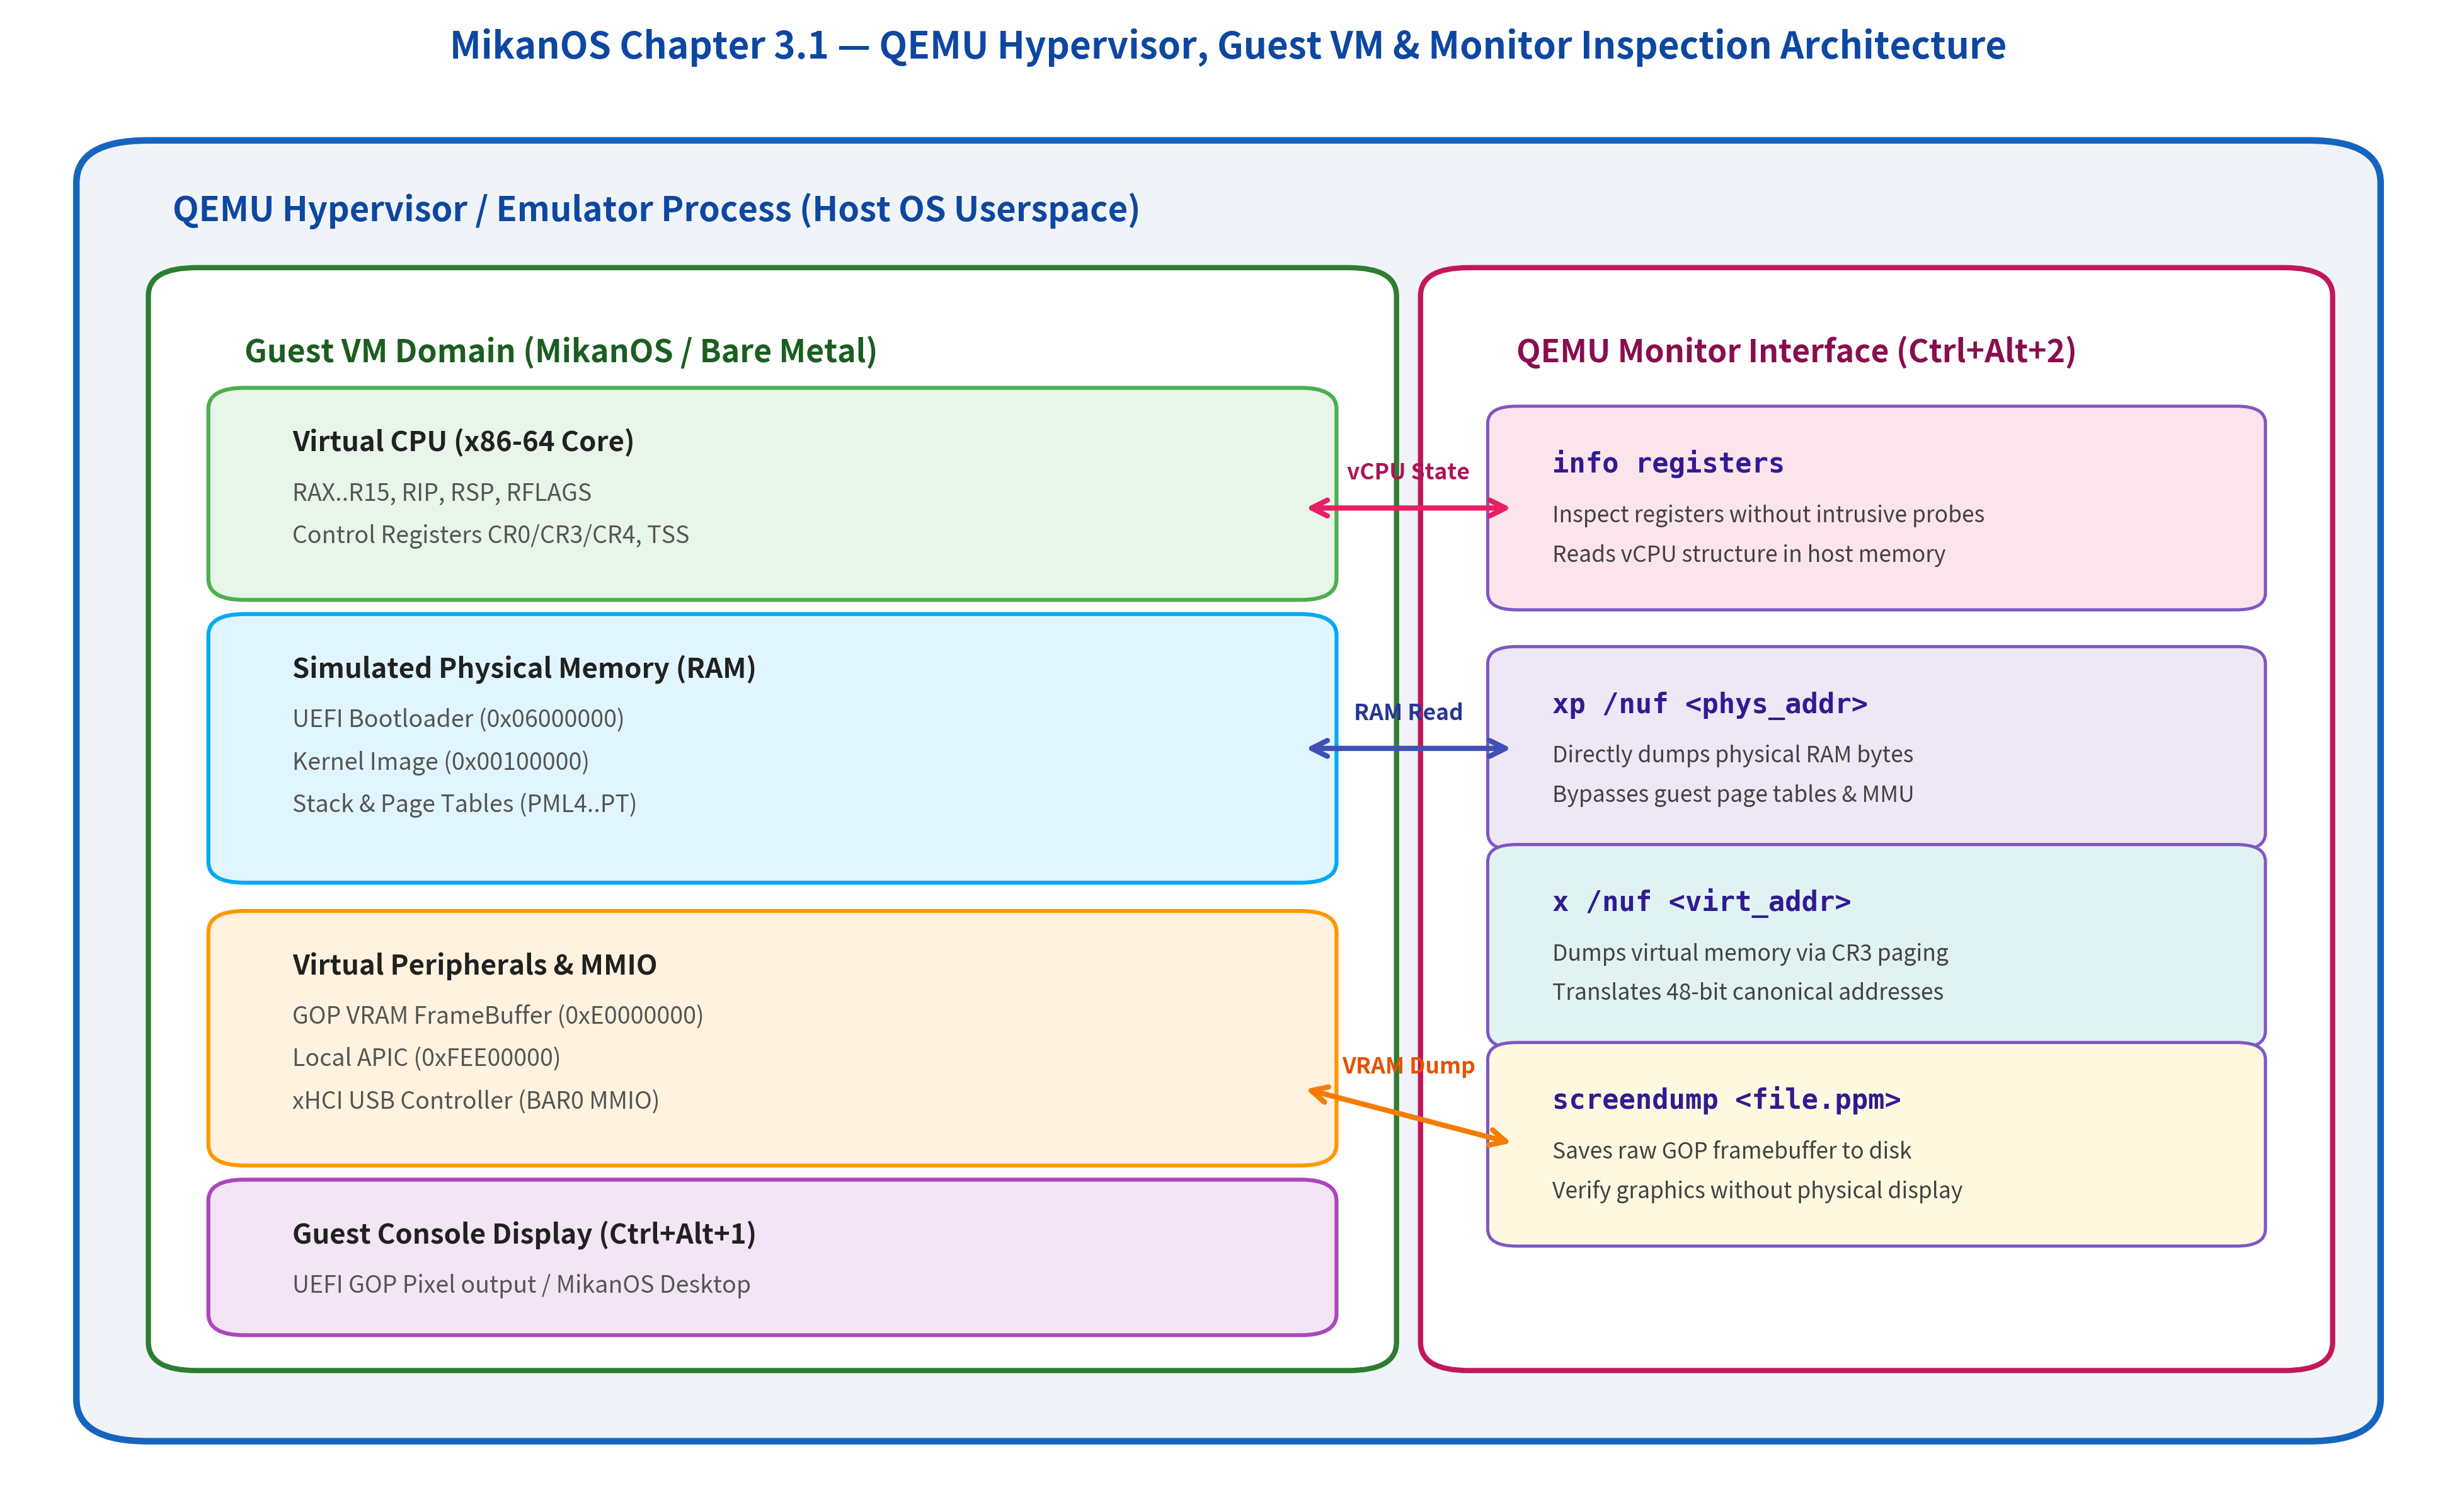

In [2]:
from common import plot_qemu_monitor_architecture
from IPython.display import Image, display

fig1_path = "result/fig3_01_qemu_monitor_architecture.png"
plot_qemu_monitor_architecture(fig1_path)
display(Image(filename=fig1_path, width=800))


## 3. CPU レジスタの完全検査: `info registers`

QEMU モニタで最も多用するコマンドが **`info registers`**（省略形: `i r`）です。
このコマンドを実行すると、x86-64 vCPU が保持する全レジスタの現在値が瞬時にダンプされます。

### 3.1 レジスタ出力例と各フィールドの解読

```text
(qemu) info registers
RAX=0000000000000000 RBX=00000000067a3018 RCX=0000000000000002 RDX=0000000000000000
RSI=00000000067b4100 RDI=00000000067a2f18 RBP=0000000007fe3e20 RSP=0000000007fe3dc0
R8 =0000000000000000 R9 =0000000000000000 R10=0000000000000000 R11=0000000000000000
R12=0000000000000000 R13=0000000000000000 R14=0000000000000000 R15=0000000000000000
RIP=000000000678f142 RFL=00000206 [----I-P-] CPL=0 II=0 A20=1 SMM=0 HLT=0
CS=0038 DS=0030 ES=0030 FS=0030 GS=0030 SS=0030
CR0=80010033 CR2=0000000000000000 CR3=0000000007fa0000 CR4=000006f0
```

この出力は、OS カーネルがクラッシュした際に**「CPU が今どの命令を実行しようとして死んだのか」「スタックはどこを指しているか」「ページングや割り込みは有効化されていたか」**を雄弁に物語っています。

### 3.2 4大レジスタカテゴリの役割と診断ポイント

#### ① 汎用レジスタ (General Purpose Registers: GPR)
- `RAX`〜`RDX`, `RSI`, `RDI`, `RBP`, `RSP`, `R8`〜`R15`:
  - 演算やポインタ参照に使われる64ビットレジスタ。
  - 特に **`RSP` (Stack Pointer)** は最重要です。`RSP` が `0` や異常な値（例: `0xffffffffffffffff`）になっていれば、スタックオーバーフローやスタックポインタの破壊（アライメント不正など）が疑われます。
  - System V AMD64 ABI では、関数の第1引数は `RDI`、第2引数は `RSI`、第3引数は `RDX`、第4引数は `RCX` で渡されます。

#### ② 命令ポインタ (RIP: Instruction Pointer)
- **`RIP`**:
  - 次に実行される機械語命令のメモリアドレス。
  - カーネルのエントリポイントが `0x100000` なのに、クラッシュ時の `RIP` が `0x0000000000000000`（NULLジャンプ）や `0xdeadbeef` になっていれば、不正な関数ポインタ呼び出しやリターンアドレスの破壊（バッファオーバーラン）が発生したことが一目で分かります。

#### ③ フラグレジスタ (RFLAGS)
- `RFL`: CPU の演算状態およびシステムフラグ（32ビット）。
- `[----I-P-]` 表記:
  - **`I` (Interrupt Flag: bit 9)**: 外部ハードウェア割り込みの許可フラグ。`I` が立っていれば割り込み許可（`STI` 状態）、消えていれば割り込み禁止（`CLI` 状態）。
  - **`P` (Parity Flag: bit 2)** / **`Z` (Zero Flag: bit 6)** / **`C` (Carry Flag: bit 0)**: 直前の演算結果。

#### ④ 制御レジスタ (Control Registers: CR0, CR2, CR3, CR4)
OS カーネルの生死を握る最重要レジスタ群です：

| レジスタ | 主要ビット | 名称・機能 | MikanOS での意味 |
|---|---|---|---|
| **`CR0`** | bit 31 (`PG`) | **Paging Enable** | `1` のときページング有効。`0` のとき無効。 |
| | bit 16 (`WP`) | **Write Protect** | `1` のとき特権（Ring 0）でも読み取り専用ページへの書き込みを禁止。 |
| | bit 0 (`PE`) | **Protection Enable** | `1` のときプロテクトモード / ロングモード。 |
| **`CR2`** | 64-bit | **Page Fault Linear Address** | **ページフォルト（#PF）発生時に、アクセス失敗した仮想アドレス**が自動格納される。クラッシュ解析の生命線！ |
| **`CR3`** | 64-bit | **Page Table Root (PML4)** | 4階層ページテーブルの最上位テーブル（PML4）の**物理メモリアドレス**。 |
| **`CR4`** | bit 9 (`OSFXSR`)| **SSE Fast FXSAVE/FXRSTOR** | `1` で SSE/AVX 浮動小数点演算命令を OS がサポート。 |
| | bit 5 (`PAE`) | **Physical Address Extension** | `1` で 64ビット物理アドレス拡張有効（x86-64 では必須 `1`）。 |

> [!TIP]
> **クラッシュ診断の鉄則**:
> OS が原因不明でクラッシュしたときは、まず `info registers` を打ち、
> 1. `CR2` に怪しいアドレス（例: `0x0` や `0xffff...`）が入っていないか確認する（ページフォルトの証拠）。
> 2. `RIP` が意図した関数コードの範囲内にあるか確認する。
> 3. `RSP` が有効なスタック領域を指しているか確認する。


## 4. 物理メモリの直接検査: `xp` コマンド

### 4.1 `xp` コマンドの構文規則 (`/nuf addr`)

**`xp` (eXamine Physical memory)** は、物理メモリアドレス上の生バイト列を直接ダンプするコマンドです。
ページングが有効化された後でも、ページテーブルを介さずに物理 RAM の実データを検査できるため、**「カーネルの ELF バイナリが正しく物理メモリに配置されたか」「スタックに正しい戻りアドレスが積まれているか」**を完璧に実証できます。

構文は以下の通りです：

$$\text{xp}\quad /\underbrace{n}_{\text{count}}\underbrace{u}_{\text{unit}}\underbrace{f}_{\text{format}}\quad \text{address}$$

| パラメータ | 記号 | 意味と指定可能な値 |
|---|:---:|---|
| **カウント ($n$)** | 整数 | 表示する要素数（例: `4`, `16`, `64`。省略時は `1`）。 |
| **単位 ($u$)** | **`b`** | **Byte (1バイト, 8ビット)** |
| | **`h`** | **Halfword (2バイト, 16ビット)** |
| | **`w`** | **Word (4バイト, 32ビット, デフォルト)** |
| | **`g`** | **Giant Word (8バイト, 64ビット)** |
| **書式 ($f$)** | **`x`** | **16進数 (Hexadecimal, デフォルト)** |
| | **`d`** | 符号付き10進数 (Signed Decimal) |
| | **`u`** | 符号なし10進数 (Unsigned Decimal) |
| | **`c`** | ASCII 文字 (Character) |
| | **`i`** | 機械語命令逆アセンブル (Instruction asm) |

### 4.2 リトルエンディアン（Little-Endian）とダンプ出力の読み方

x86-64 アーキテクチャは**リトルエンディアン**を採用しています。
すなわち、多バイト整数（16bit / 32bit / 64bit）をメモリに配置する際、**最下位バイト（LSB: Least Significant Byte）が最も小さいアドレス（先頭）**に格納されます。

例えば、物理アドレス `0x100000` から以下の8バイトが並んでいたとします：

```text
物理アドレス: 0x100000  0x100001  0x100002  0x100003  0x100004  0x100005  0x100006  0x100007
生バイト列:     48        83        EC        28        E8        12        00        00
```

これを異なる単位で `xp` コマンドでダンプすると、出力は以下のように変化します：

1. **バイト単位ダンプ (`xp /8bx 0x100000`)**:
   - `0x0000000000100000: 0x48 0x83 0xec 0x28 0xe8 0x12 0x00 0x00`
   - メモリ上の物理バイト並びがそのまま出力されます。
2. **32ビットワード単位ダンプ (`xp /2wx 0x100000`)**:
   - `0x0000000000100000: 0x28ec8348 0x000012e8`
   - 前半4バイト `[48, 83, EC, 28]` が、リトルエンディアンにより逆順に結合され `0x28EC8348` となります。
3. **64ビットジャイアントワード単位ダンプ (`xp /1gx 0x100000`)**:
   - `0x0000000000100000: 0x000012e828ec8348`
   - 8バイト全体が逆順に結合され、単一の64ビット整数 `0x000012e828ec8348` として表示されます。

このリトルエンディアン変換の数理は、以下の式で表されます：

$$\text{Value}_{64} = \sum_{i=0}^{7} \text{Byte}[i] \times 2^{8i} = \text{Byte}[0] + \text{Byte}[1]\cdot 2^8 + \text{Byte}[2]\cdot 2^{16} + \dots + \text{Byte}[7]\cdot 2^{56}$$

### 4.3 文字列の確認 (`xp /nuf` with `c`)
カーネルやブートローダがメモリ上に配置した文字列（ASCII）を確認したい場合は、`xp /32bc <addr>` を使用します。印字可能文字（ASCII 32〜126）はそのまま `'A'` のように表示され、制御文字やヌル文字は `.` や16進数で表示されます。


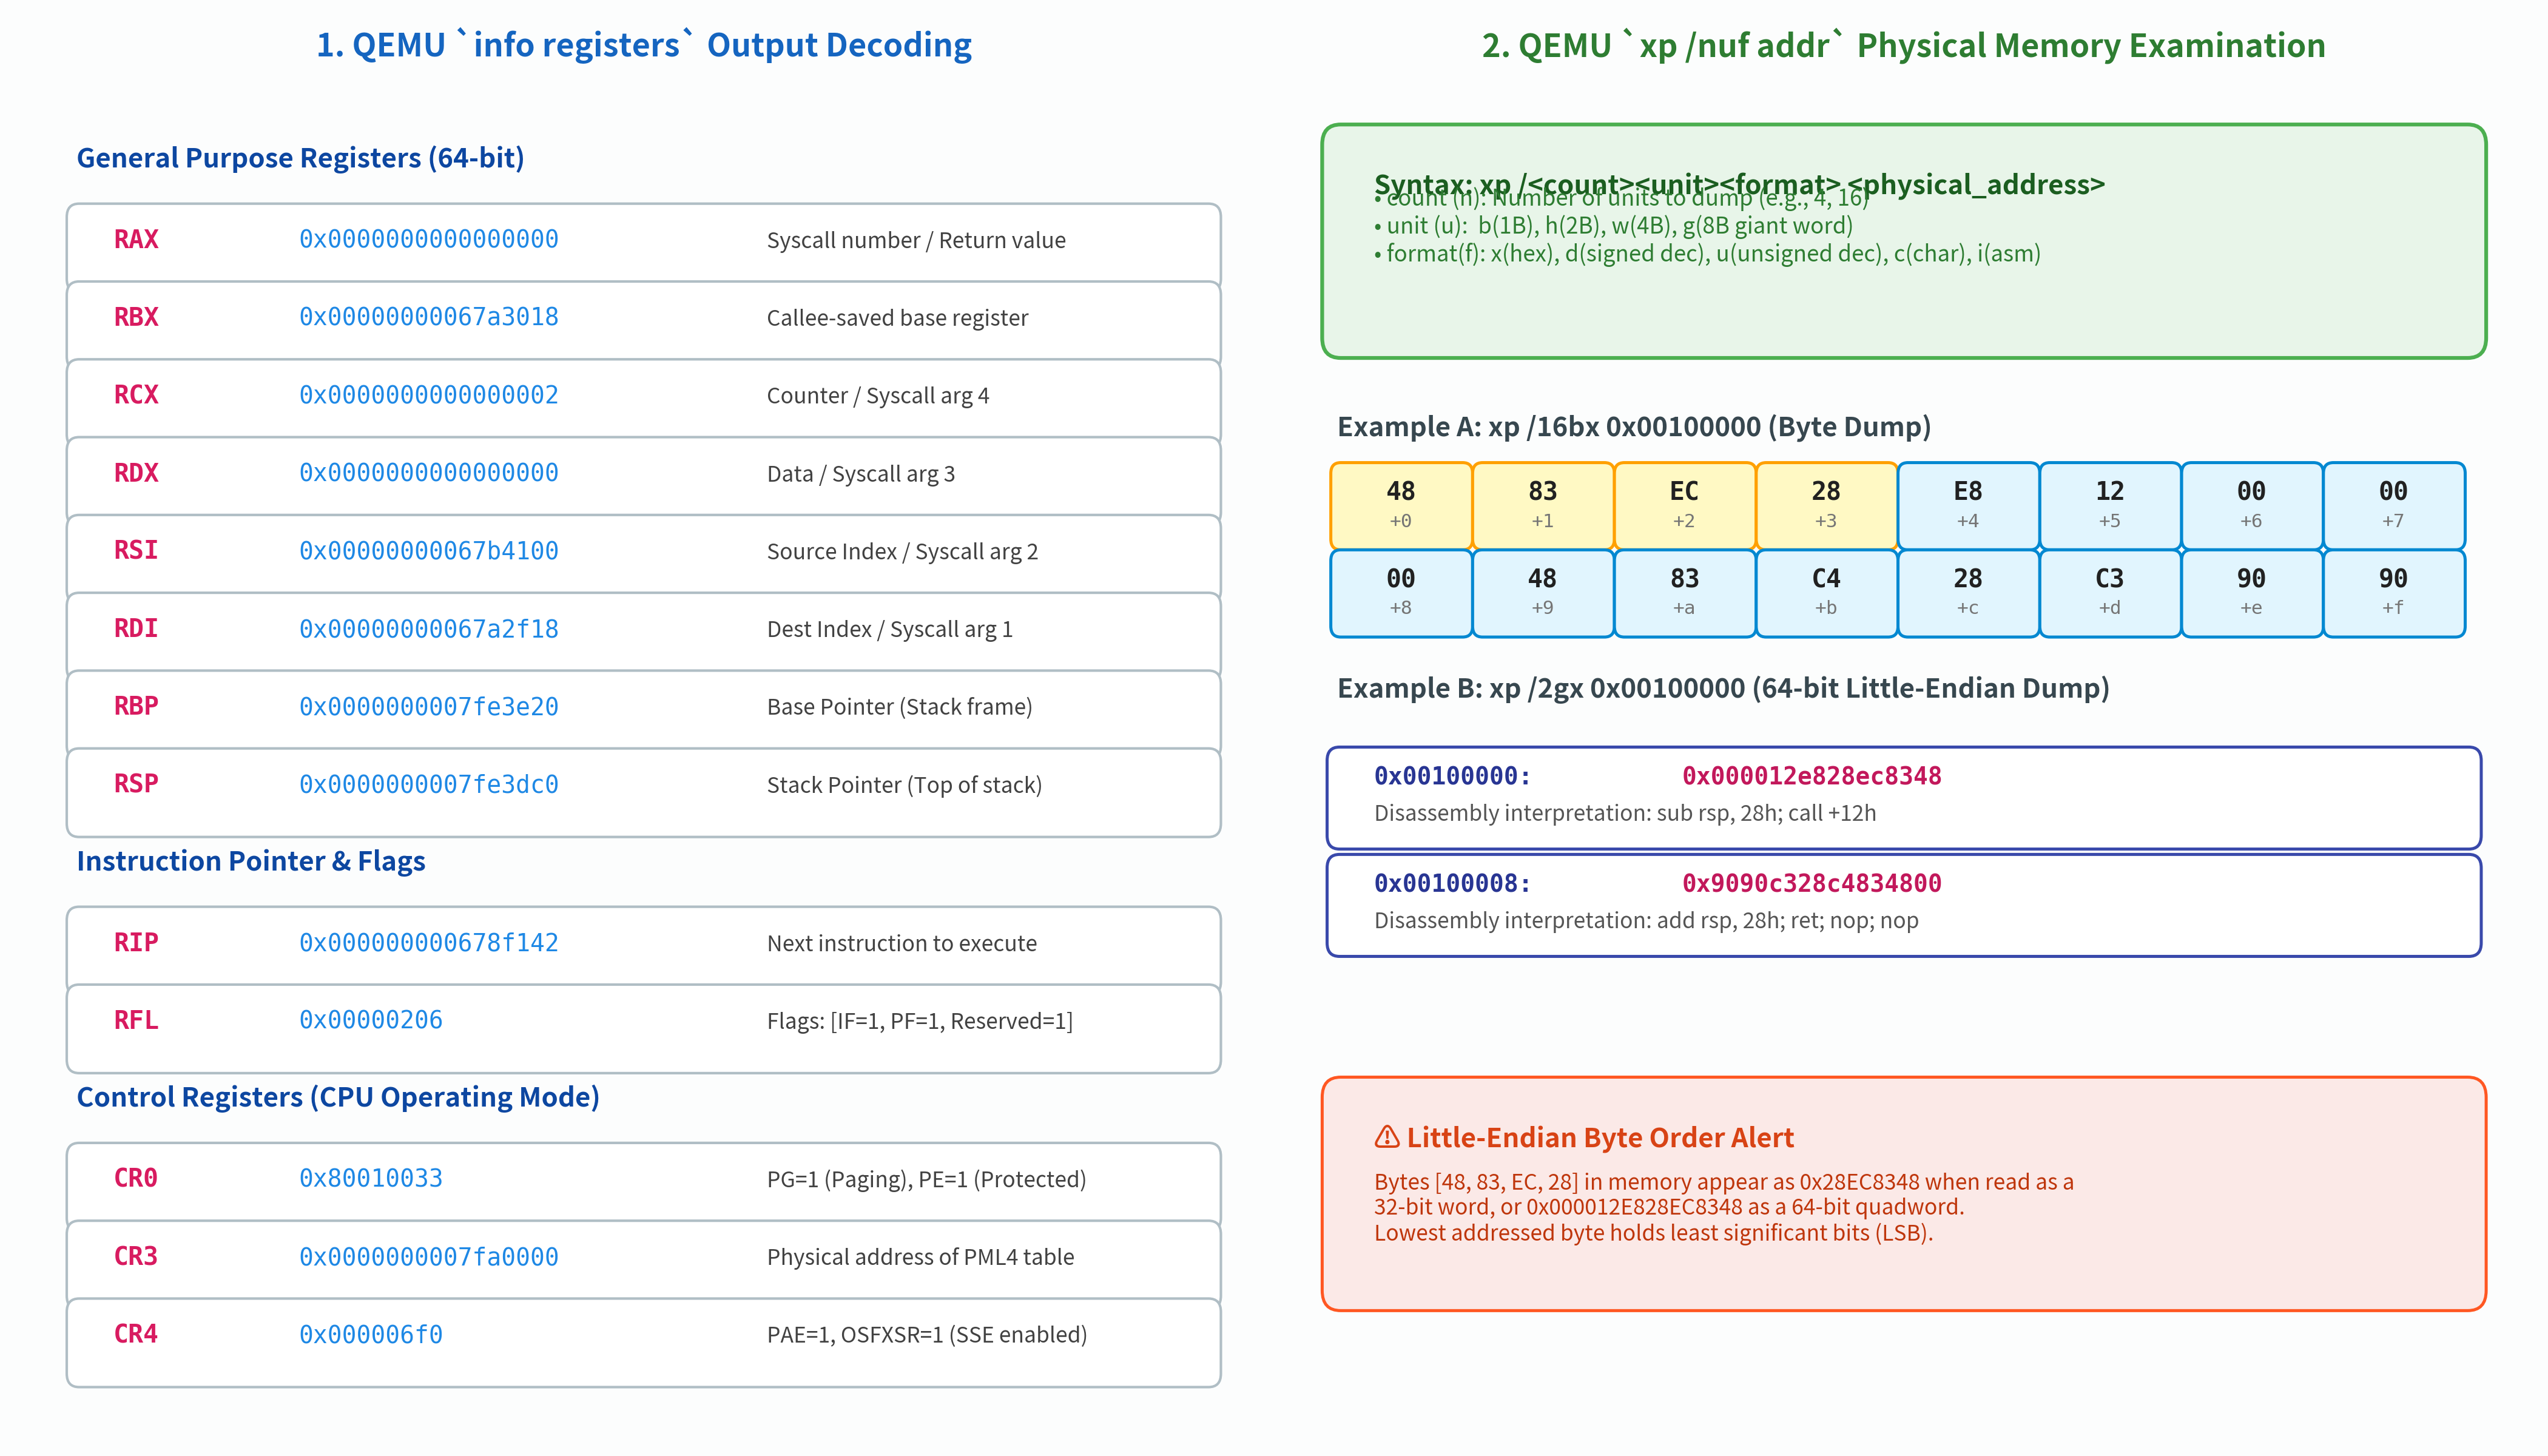

In [3]:
from common import plot_qemu_registers_and_memory_dump
from IPython.display import Image, display

fig2_path = "result/fig3_02_qemu_registers_and_memory_dump.png"
plot_qemu_registers_and_memory_dump(fig2_path)
display(Image(filename=fig2_path, width=800))


## 5. 仮想メモリ検査 `x` とその他の主要モニタコマンド

### 5.1 仮想メモリ検査 (`x /nuf <virtual_addr>`)
- `x` コマンドは、**仮想アドレス（論理アドレス）**を指定してメモリを検査します。
- QEMU は現在の `CR3` レジスタが指す4階層ページテーブル（PML4 → PDP → PD → PT）を自動的に手繰り（Page Table Walk）、対応する物理アドレスを特定して内容をダンプします。
- 第19章でアプリケーション仮想アドレス空間（前半カーネル空間・後半アプリ空間）を導入した際、ページマッピングが正しく設定されているかを確認する決定打となります。
- ※なお、ブート初期（第3章時点）は恒等マッピング（Identity Mapping: 仮想アドレス == 物理アドレス）が設定されているため、`x` と `xp` は同じ結果を返します。

### 5.2 実行制御と画面キャプチャコマンド一覧

| コマンド | 省略形 | 構文例 | 役割・活用シーン |
|---|:---:|---|---|
| **`stop`** | - | `stop` | ゲスト OS の vCPU 実行を一時停止（フリーズ）させる。レジスタをゆっくり検査したい時に使用。 |
| **`cont`** | **`c`** | `c` | 一時停止したゲスト OS の実行を再開する。 |
| **`print`** | **`p`** | `p/x $rax + 0x10` | 任意の C言語風数式やレジスタ値、メモリアドレスの四則演算を即座に計算して表示する。 |
| **`screendump`** | - | `screendump screen.ppm` | **現在の GOP フレームバッファ画面を PPM 形式画像ファイルとしてホスト上に保存**する。画面描画の検証に絶大な威力を発揮！ |
| **`info mem`** | - | `info mem` | 現在ページテーブルによって有効化されている仮想メモリ領域の開始・終了アドレスとアクセス権限（rwx）を一覧表示。 |
| **`info pci`** | - | `info pci` | 第6章で扱う PCI バス上のデバイス一覧（USB 3.0 xHCI コントローラのバス・デバイス・ファンクション番号）を表示。 |
| **`quit`** | **`q`** | `q` | QEMU 仮想マシンを即座に終了する。 |


## 6. C++20 による QEMU モニタ・レジスタ・物理メモリシミュレータの実装と対話実行

本リポジトリでは、ホスト側環境（Google Colab およびローカル PC）でも QEMU モニタの動作原理を深く体感できるよう、**C++20 によるスタンドアロン検証バイナリ (`src/ch03/qemu_monitor_sim.cpp`)** を実装しています。

以下のセルを実行してコンパイルおよびテストを実行し、CPU レジスタのビットフラグ判定、物理メモリのリトルエンディアン多バイト変換、および `info registers` / `xp` 出力フォーマッタが正しく動作することを検証します。


In [4]:
!cmake -B ../build -S ..
!cmake --build ../build --target ch03_qemu_monitor_sim
!../build/bin/ch03_qemu_monitor_sim


-- Configuring done (0.0s)
-- Generating done (0.0s)
-- Build files have been written to: /home/student/Documents/GitHub/study-mikanos/build


[100%] Built target ch03_qemu_monitor_sim


  MikanOS Chapter 3.1: QEMU Monitor & x86-64 Debugging Infrastructure          

[1] x86-64 CPU Register Model & Flags Verification:
  - CR0 Paging (PG bit 31)      : ENABLED (1)
  - CR0 Protected Mode (PE bit) : ENABLED (1)
  - RFLAGS Interrupt Flag (IF)  : ENABLED (1)
  - `info registers` Format     : PASSED

[2] Physical Memory Inspection (`xp /nuf addr`) Verification:
  - RAM Write & Readback        : PASSED
  - `xp /4bx` Byte Dump Formatter: PASSED
  - `xp /1gx` Little-Endian Math: PASSED (0x000012e828ec8348)
  - Multi-line Formatting       : PASSED

[3] Simulated QEMU Monitor `info registers` Output:
RAX=0000000000000000 RBX=0000000000000000 RCX=0000000000000000 RDX=0000000000000000
RSI=0000000000000000 RDI=0000000000000000 RBP=0000000000000000 RSP=0000000007fe3dc0
R8 =0000000000000000 R9 =0000000000000000 R10=0000000000000000 R11=0000000000000000
R12=0000000000000000 R13=0000000000000000 R14=0000000000000000 R15=0000000000000000
RIP=0000000000100000 RFL=00000202 [----I---]
CS=00

## 7. Python による対話型 QEMU モニタ REPL シミュレーション

次に、共通モジュール `common/os_sim.py` に配備された **`QemuMonitorEngine`** を用いて、Python 上で QEMU モニタの対話的デバッグ体験を行います。

仮想 RAM のアドレス `0x00100000` に MikanOS のカーネル初期化コード（機械語）を書き込み、`xp /4bx`, `xp /2wx`, `xp /1gx`, `info registers`, `print` コマンドを実行して、QEMU がどのようにハードウェアを検査するかを観察します。


In [5]:
from common import QemuMonitorEngine, CpuRegisterState

# 1. QEMU モニタエンジンの初期化 (RAM 16MiB)
mon = QemuMonitorEngine(ram_size=16 * 1024 * 1024)

# 2. カーネルエントリポイント (0x100000) にサンプル機械語コードを配置
# x86-64 アセンブリ:
#   sub rsp, 0x28       ; 48 83 ec 28
#   call +0x12          ; e8 12 00 00 00
#   add rsp, 0x28       ; 48 83 c4 28
#   ret                 ; c3
kernel_machine_code = bytes([
    0x48, 0x83, 0xEC, 0x28,
    0xE8, 0x12, 0x00, 0x00,
    0x00, 0x48, 0x83, 0xC4,
    0x28, 0xC3, 0x90, 0x90
])
mon.ram.write_bytes(0x00100000, kernel_machine_code)

# 3. CPU レジスタ状態を設定 (MikanOS ブートローダからカーネル呼び出し直前の状態)
mon.regs.rip = 0x00100000
mon.regs.rsp = 0x07FE3DC0
mon.regs.rdi = 0x067A2F18  # 第1引数: FrameBufferConfig 構造体のアドレス
mon.regs.cr0 = 0x80010033  # PG=1, PE=1
mon.regs.cr3 = 0x07FA0000  # PML4 ページテーブルルート

print("=== [1] QEMU モニタ: CPU レジスタ状態のダンプ (`info registers`) ===")
print(mon.execute_command("info registers"))
print()

print("=== [2] QEMU モニタ: 物理メモリの生バイトダンプ (`xp /8bx 0x100000`) ===")
print(mon.execute_command("xp /8bx 0x100000"))
print()

print("=== [3] QEMU モニタ: 32ビットワード単位ダンプ (`xp /4wx 0x100000`) ===")
print(mon.execute_command("xp /4wx 0x100000"))
print()

print("=== [4] QEMU モニタ: 64ビットジャイアントワード単位ダンプ (`xp /2gx 0x100000`) ===")
print(mon.execute_command("xp /2gx 0x100000"))
print()

print("=== [5] QEMU モニタ: 式評価コマンド (`print`) ===")
print("RSP から 64バイト引いたスタック予約アドレス:", mon.execute_command("print rsp - 64"))
print()

print("=== [6] QEMU モニタ: ヘルプメッセージ (`help`) ===")
print(mon.execute_command("help"))


=== [1] QEMU モニタ: CPU レジスタ状態のダンプ (`info registers`) ===
RAX=0000000000000000 RBX=0000000000000000 RCX=0000000000000000 RDX=0000000000000000
RSI=0000000000000000 RDI=00000000067a2f18 RBP=0000000000000000 RSP=0000000007fe3dc0
R8 =0000000000000000 R9 =0000000000000000 R10=0000000000000000 R11=0000000000000000
R12=0000000000000000 R13=0000000000000000 R14=0000000000000000 R15=0000000000000000
RIP=0000000000100000 RFL=00000202 [----I---]
CS=0038 DS=0030 ES=0030 FS=0030 GS=0030 SS=0030
CR0=80010033 CR2=0000000000000000 CR3=0000000007fa0000 CR4=000006f0

=== [2] QEMU モニタ: 物理メモリの生バイトダンプ (`xp /8bx 0x100000`) ===
0x0000000000100000: 0x48 0x83 0xec 0x28 0xe8 0x12 0x00 0x00

=== [3] QEMU モニタ: 32ビットワード単位ダンプ (`xp /4wx 0x100000`) ===
0x0000000000100000: 0x28ec8348 0x000012e8 0xc4834800 0x9090c328

=== [4] QEMU モニタ: 64ビットジャイアントワード単位ダンプ (`xp /2gx 0x100000`) ===
0x0000000000100000: 0x000012e828ec8348 0x9090c328c4834800

=== [5] QEMU モニタ: 式評価コマンド (`print`) ===
RSP から 64バイト引いたスタック予約アドレス: $0x7fe3d80

=== [

## 8. 本節のまとめと次節（3.2 レジスタ）への展望

### 8.1 本節で学んだ最重要ポイント

1. **QEMU モニタはベアメタル初期開発の最強の救世主**:
   - 画面描画ドライバも `printk` も存在しない初期 OS 開発において、外部から非侵襲的（副作用ゼロ）にハードウェアを検査できる必須ツール。
2. **コンソール切り替えのキーバインド**:
   - `Ctrl + Alt + 2` でモニタ画面、`Ctrl + Alt + 1` でゲスト画面復帰。CLI では `-monitor stdio` を活用。
3. **`info registers` による CPU 状態の即時把握**:
   - `RIP`（次に実行する命令アドレス）、`RSP`（スタックポインタ）、`RFLAGS`（割り込み許可フラグ `IF`）。
   - `CR0`（ページング `PG`・プロテクトモード `PE`）、`CR2`（ページフォルト発生アドレス）、`CR3`（PML4 ページテーブル物理アドレス）。
4. **`xp /nuf addr` による物理メモリの直接解読**:
   - 単位（`b`=1B, `h`=2B, `w`=4B, `g`=8B）と書式（`x`=16進数, `c`=文字, `d`=10進数）。
   - x86-64 のリトルエンディアン特性によるバイト並びと多バイト整数の逆順結合メカニズム。

---

### 🚀 次節への接続: 3.2 レジスタ (`x86_64 Registers`)

本節で QEMU モニタの `info registers` を使いこなせるようになったことで、CPU 内部のレジスタ状態をいつでも覗き見られる準備が整いました。

次節 **3.2「レジスタ」** では、今回登場したレジスタ群をさらに一歩深掘りし、
- **汎用レジスタ（RAX〜R15）の64bit / 32bit / 16bit / 8bit サブ領域アクセス（EAX, AX, AL, AH等）**
- **呼び出し規約（System V AMD64 ABI）における引数レジスタと Callee-saved レジスタ**
- **制御レジスタ（CR0〜CR4）の全ビットマスク**

を体系的にマスターし、いよいよカーネル本体の機械語・アセンブリコードの実装へと進みます！
